--- TAHAP 1: MEMUAT DAN PRE-PROCESSING DATA ---
Dataset berhasil dimuat!

--- TAHAP 2: PERHITUNGAN CERTAINTY FACTOR ---


,age,cp,trestbps,chol,cf_percentage,risk_level
0,63,typical angina,145.0,233.0,93.40,Risiko Tinggi
1,67,asymptomatic,160.0,286.0,93.07,Risiko Tinggi
2,67,asymptomatic,120.0,229.0,72.00,Risiko Tinggi
3,37,non-anginal,130.0,250.0,86.50,Risiko Tinggi
4,41,atypical angina,130.0,204.0,88.00,Risiko Tinggi
5,56,atypical angina,120.0,236.0,70.00,Risiko Sedang
6,62,asymptomatic,140.0,268.0,82.00,Risiko Tinggi
7,57,asymptomatic,120.0,354.0,55.00,Risiko Sedang
8,63,asymptomatic,130.0,254.0,87.40,Risiko Tinggi
9,53,asymptomatic,140.0,203.0,60.00,Risiko Sedang



--- TAHAP 3: EVALUASI PERFORMA SISTEM ---
Tingkat Akurasi Algoritma Certainty Factor: 46.30%

Laporan Klasifikasi Detail:
              precision    recall  f1-score   support

 Negatif PJK       0.23      0.08      0.12       411
 Positif PJK       0.51      0.77      0.61       509

    accuracy                           0.46       920
   macro avg       0.37      0.43      0.37       920
weighted avg       0.38      0.46      0.39       920



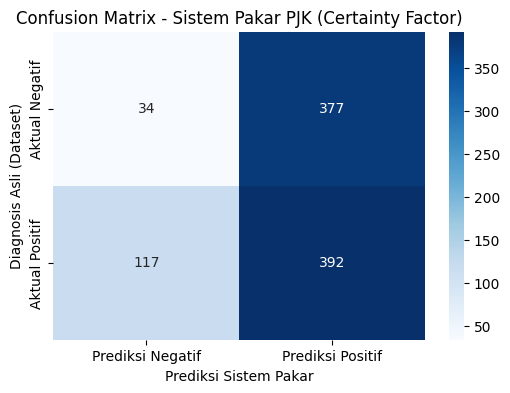

In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# 1. PRE-PROCESSING DATA
print("--- TAHAP 1: MEMUAT DAN PRE-PROCESSING DATA ---")
file_path = 'heart_disease_uci.csv'

try:
    df = pd.read_csv(file_path)
    print("Dataset berhasil dimuat!")
except FileNotFoundError:
    print("File tidak ditemukan. Pastikan file CSV sudah di-upload ke Colab.")

# Membersihkan data numerik
df['trestbps'] = pd.to_numeric(df['trestbps'], errors='coerce')
df['chol'] = pd.to_numeric(df['chol'], errors='coerce')
df['thalch'] = pd.to_numeric(df['thalch'], errors='coerce') # Kolom max heart rate bernama thalch
df = df.fillna(df.median(numeric_only=True))

# 2. BASIS PENGETAHUAN PAKAR (ATURAN CERTAINTY FACTOR)
def get_cf_symptoms(row):
    symptoms_cf = []

    # Aturan 1: Tipe Nyeri Dada (cp)
    # Di dataset ini tipenya teks: 'typical angina', 'atypical angina', 'non-anginal', 'asymptomatic'
    if row['cp'] in ['typical angina', 'atypical angina', 'non-anginal']:
        mb, md = 0.80, 0.10
        symptoms_cf.append(mb - md)

    # Aturan 2: Tekanan Darah Istirahat (trestbps) > 140 mmHg
    if row['trestbps'] > 140:
        mb, md = 0.60, 0.15
        symptoms_cf.append(mb - md)

    # Aturan 3: Kolesterol (chol) > 240 mg/dl
    if row['chol'] > 240:
        mb, md = 0.65, 0.10
        symptoms_cf.append(mb - md)

    # Aturan 4: Detak Jantung Maksimal (thalch) < 150 bpm
    if row['thalch'] < 150:
        mb, md = 0.50, 0.20
        symptoms_cf.append(mb - md)

    # Aturan 5: Hasil EKG Istirahat (restecg)
    # Tipe teks: 'lv hypertrophy', 'st-t abnormality', 'normal'
    if row['restecg'] in ['lv hypertrophy', 'st-t abnormality']:
        mb, md = 0.70, 0.10
        symptoms_cf.append(mb - md)

    return symptoms_cf

# 3. PERHITUNGAN CERTAINTY FACTOR (CF COMBINE)
print("\n--- TAHAP 2: PERHITUNGAN CERTAINTY FACTOR ---")
def calculate_cf_combine(cf_list):
    if len(cf_list) == 0:
        return 0.0
    elif len(cf_list) == 1:
        return cf_list[0]

    # CF_combine = CF_old + CF_new * (1 - CF_old)
    cf_combine = cf_list[0]
    for i in range(1, len(cf_list)):
        cf_combine = cf_combine + cf_list[i] * (1 - cf_combine)

    return cf_combine

# Kalkulasi sistem
df['cf_list'] = df.apply(get_cf_symptoms, axis=1)
df['cf_final_score'] = df['cf_list'].apply(calculate_cf_combine)
df['cf_percentage'] = round(df['cf_final_score'] * 100, 2)

# 4. KLASIFIKASI TINGKAT RISIKO
def classify_risk(percentage):
    if percentage < 40:
        return 'Risiko Rendah'
    elif 40 <= percentage <= 70:
        return 'Risiko Sedang'
    else:
        return 'Risiko Tinggi'

df['risk_level'] = df['cf_percentage'].apply(classify_risk)

# Tampilkan sampel hasil perhitungan
display(df[['age', 'cp', 'trestbps', 'chol', 'cf_percentage', 'risk_level']].head(10))

# 5. EVALUASI SISTEM (CONFUSION MATRIX & AKURASI)
print("\n--- TAHAP 3: EVALUASI PERFORMA SISTEM ---")
# Menentukan kolom target/ground truth ('num')
target_col = 'num'

# Binarisasi hasil Sistem Pakar
df['system_prediction'] = df['risk_level'].apply(lambda x: 0 if x == 'Risiko Rendah' else 1)

# Normalisasi target asli Kaggle (jika nilai > 0 maka dianggap positif PJK)
df['actual_target'] = df[target_col].apply(lambda x: 1 if x > 0 else 0)

# Menghitung Confusion Matrix dan Akurasi
conf_matrix = confusion_matrix(df['actual_target'], df['system_prediction'])
accuracy = accuracy_score(df['actual_target'], df['system_prediction'])

print(f"Tingkat Akurasi Algoritma Certainty Factor: {accuracy * 100:.2f}%\n")
print("Laporan Klasifikasi Detail:")
print(classification_report(df['actual_target'], df['system_prediction'], target_names=['Negatif PJK', 'Positif PJK']))

# Visualisasi Confusion Matrix
plt.figure(figsize=(6,4))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Prediksi Negatif', 'Prediksi Positif'],
            yticklabels=['Aktual Negatif', 'Aktual Positif'])
plt.title('Confusion Matrix - Sistem Pakar PJK (Certainty Factor)')
plt.ylabel('Diagnosis Asli (Dataset)')
plt.xlabel('Prediksi Sistem Pakar')
plt.show()

In [ ]:
print(df.shape)
print(df['actual_target'].value_counts())

(920, 22)
actual_target
1    509
0    411
Name: count, dtype: int64
